# Week 2 Day 2 — Orchestration (Reference Notebook)

First multi-agent project with the OpenAI Agents SDK.

Topics covered:

1. **Email / push delivery** — SMTP setup with Pushover fallback
2. **Orchestration by code** — you call agents in parallel (`asyncio.gather`), then pick/send
3. **Orchestration by LLMs via tools** — manager agent calls specialist agents as tools
4. **Orchestration by LLMs via handoffs** — manager drafts, then transfers to a sender agent

Key contrast:
- **By code** → deterministic control flow (you write the steps)
- **By LLM** → the model decides which tools/handoffs to use (more flexible, less predictable)

Docs: https://openai.github.io/openai-agents-python/

In [1]:
# --- Imports for orchestration workflows ---
from dotenv import load_dotenv
import requests                          # Pushover HTTP API (fallback delivery)
from agents import (
    Agent,                               # LLM agent definition
    Runner,                              # await Runner.run(...) / run_streamed(...)
    trace,                               # Named spans in the OpenAI traces UI
    function_tool,                       # Decorate Python functions as agent tools
    ModelSettings,                       # e.g. force tool use with tool_choice="required"
)
from agents.extensions.visualization import draw_graph  # Graphviz diagram of agent + tools/handoffs
from openai.types.responses import ResponseTextDeltaEvent  # Streaming text deltas
import os
import asyncio                           # asyncio.gather for parallel agent runs
import smtplib                           # SMTP email send
from email.message import EmailMessage

# override=True: .env values win over already-set shell env vars
load_dotenv(override=True)

# Single model id reused across agents in this notebook
MODEL_NAME = "gpt-5.4-mini"

## Part 1: Email Setup

Agents will eventually *send* the chosen sales email. SMTP is the simple path (send-only);
Pushover is the fallback if email env vars are missing.

Required `.env` keys for email:
- `EMAIL_ADDRESS`
- `EMAIL_SMTP_SERVER` (e.g. `smtp.gmail.com`)
- `EMAIL_APP_PASSWORD` (app-specific password, not your normal login)

Common SMTP hosts: Gmail `smtp.gmail.com`, Outlook `smtp-mail.outlook.com`,
Office 365 `smtp.office365.com`, iCloud `smtp.mail.me.com`.

In [2]:
# Load SMTP settings from .env and decide whether email is usable.
EMAIL_ADDRESS = os.getenv("EMAIL_ADDRESS")
EMAIL_SMTP_SERVER = os.getenv("EMAIL_SMTP_SERVER")
EMAIL_SMTP_PORT = os.getenv("EMAIL_SMTP_PORT")  # optional; we default to 587 below
EMAIL_APP_PASSWORD = os.getenv("EMAIL_APP_PASSWORD")

if EMAIL_ADDRESS:
    print("Email address is set")
else:
    print("Email address is not set")

if EMAIL_SMTP_SERVER:
    print("Email SMTP server is set")
else:
    print("Email SMTP server is not set")

if EMAIL_APP_PASSWORD:
    print("Email app password is set")
else:
    print("App password is not set")

# Truthy only when all three required values are present.
USE_EMAIL = EMAIL_ADDRESS and EMAIL_SMTP_SERVER and EMAIL_APP_PASSWORD

if USE_EMAIL:
    print("Email is set up and we will try using it")
else:
    print("Email is not set up; we will use Pushover instead")

Email address is set
Email SMTP server is set
Email app password is set
Email is set up and we will try using it


In [3]:
# Send a multipart email (plain text + HTML) via SMTP STARTTLS on port 587.
# To=From for lab demos so you email yourself; change To for real prospects.
def send_email(subject, text_body, html_body):
    msg = EmailMessage()
    msg["From"] = EMAIL_ADDRESS
    msg["To"] = EMAIL_ADDRESS
    msg["Subject"] = subject
    msg.set_content(text_body)                         # text/plain part
    msg.add_alternative(html_body, subtype="html")      # text/html alternative

    port = int(EMAIL_SMTP_PORT) if EMAIL_SMTP_PORT else 587
    with smtplib.SMTP(EMAIL_SMTP_SERVER, port) as server:
        server.starttls()
        server.login(EMAIL_ADDRESS, EMAIL_APP_PASSWORD)
        server.send_message(msg)

In [4]:
# Smoke-test SMTP before wiring into agents (check your inbox).
send_email(
    "Testing, testing, 123",
    "Fingers crossed..",
    "<html><body><strong>Fingers</strong> crossed..</body></html>",
)

### Fallback strategy — Pushover

If email is not configured (`USE_EMAIL` is false), `send_message` routes to a push notification instead.
Requires `PUSHOVER_USER` and `PUSHOVER_TOKEN` in `.env`.

In [5]:
# Sanity-check Pushover credentials (user keys often start with "u", tokens with "a").
pushover_user = os.getenv("PUSHOVER_USER")
pushover_token = os.getenv("PUSHOVER_TOKEN")
pushover_url = "https://api.pushover.net/1/messages.json"

if pushover_user:
    if pushover_user.startswith("u"):
        print("Pushover user found and looks good")
    else:
        print("Pushover user found but doesn't start with u")
else:
    print("Pushover user not found")

if pushover_token:
    if pushover_token.startswith("a"):
        print("Pushover token found and looks good")
    else:
        print("Pushover token found but doesn't start with a")
else:
    print("Pushover token not found")


Pushover user found and looks good
Pushover token found and looks good


In [6]:
# Plain helper (not an agent tool yet) — posts a notification to Pushover.
def push(message):
    print(f"Push: {message}")
    payload = {
        "user": pushover_user,
        "token": pushover_token,
        "message": message,
    }
    requests.post(pushover_url, data=payload)

In [7]:
# Single delivery entry point used by the agent tool later.
# Flip USE_EMAIL (via missing/present env vars) without changing callers.
def send_message(subject, text_body, html_body):
    if USE_EMAIL:
        send_email(subject, text_body, html_body)
    else:
        push(f"{subject}\n\n{text_body}")

In [8]:
# End-to-end delivery smoke test (email or push depending on USE_EMAIL).
send_message(
    "Big news",
    "Communications are a go!",
    "<html><body>Communications are a<strong>go!</strong></body></html>",
)

## Agent Orchestration

* https://openai.github.io/openai-agents-python/multi_agent/

Two orchestration styles in this notebook:

| Style | Who decides the steps? | Example |
|---|---|---|
| **By code** | Your Python (`asyncio.gather`, then picker) | Part 2 |
| **By LLM** | The manager agent (tools / handoffs) | Parts 3–4 |

### Part 2: Orchestrating by code

You explicitly:
1. Run three style-variant sales agents **in parallel**
2. Feed their outputs to a picker agent
3. (Later) Send the winner via a tool

Predictable and easy to debug — the LLM does not invent the workflow.

In [9]:
# Shared company context + three distinct writing styles.
# Same product brief, different personas → diverse drafts for the picker.
intro = """
You are a Sales agent working for ComplAI, a company that
provides a SaaS tool for ensuring SOC2 compliance and preparing
for audits, powered by AI. You write emails.
"""

instructions1 = intro + "Your email style is professional, serious, with gravitas and credibility."
instructions2 = intro + "Your email style is witty, engaging, and humorous."
instructions3 = intro + "Your email style is concise, to the point, in the style of a busy senior executive."

In [10]:
# Three specialist writers — identical model, different instructions.
sales_agent1 = Agent(
    name="Professional Sales Agent",
    instructions=instructions1,
    model=MODEL_NAME,
)
sales_agent2 = Agent(
    name="Humorous Sales Agent",
    instructions=instructions2,
    model=MODEL_NAME,
)
sales_agent3 = Agent(
    name="Executive Sales Agent",
    instructions=instructions3,
    model=MODEL_NAME,
)


In [11]:
# Quick streaming check of one writer before running the parallel workflow.
result = Runner.run_streamed(sales_agent1, input="Write a cold sales email")
async for event in result.stream_events():
    if event.type == "raw_response_event" and isinstance(event.data, ResponseTextDeltaEvent):
        print(event.data.delta, end="", flush=True) 

Subject: Reducing SOC 2 prep from months to weeks

Hi [First Name],

Reaching out because many teams I speak with are feeling the pressure of SOC 2 preparation: scattered evidence, heavy manual work, and uncertainty heading into audit season.

ComplAI helps teams streamline SOC 2 readiness with an AI-powered platform that organizes evidence, identifies gaps, and simplifies audit preparation so your team can move faster with more confidence.

If SOC 2 is on your roadmap, I’d welcome the chance to show you how we can reduce the operational burden and make the process far more manageable.

Would you be open to a brief conversation next week?

Best regards,  
[Your Name]  
ComplAI

In [12]:
# Orchestration by code, step 1: fan-out.
# asyncio.gather runs all three writers concurrently (faster than sequential awaits).
message = "Write a cold sales email"

with trace("Parallel cold emails"):
    results = await asyncio.gather(
        Runner.run(sales_agent1, message),
        Runner.run(sales_agent2, message),
        Runner.run(sales_agent3, message),
    )

outputs = [result.final_output for result in results]
for output in outputs:
    print(output + "\n\n")

Subject: Streamlining SOC 2 readiness without adding headcount

Hi [First Name],

I’m reaching out from ComplAI. We help companies prepare for SOC 2 and stay audit-ready with an AI-powered platform designed to reduce the manual work that typically slows teams down.

For many growing organizations, compliance becomes a bottleneck: scattered evidence, repeated requests across teams, and too much time spent coordinating with auditors. ComplAI helps centralize that process and make it far more manageable.

If SOC 2 is on your roadmap this quarter, I’d be glad to share how we’re helping teams:
- organize evidence automatically
- track compliance tasks in one place
- reduce prep time ahead of audit

Would you be open to a brief call next week?

Best regards,  
[Your Name]  
ComplAI


Subject: SOC 2 without the spreadsheet sorcery?  

Hi [First Name],

Hope you’re having a productive week — or at least one with fewer compliance headaches than usual.

I’m reaching out because ComplAI helps tea

In [13]:
# Picker agent: judges drafts. Instructed to return ONLY the winning email (no preamble).
decision = """
You pick the best cold sales email from the given options.
Imagine you are a customer and pick the one you are most likely
to respond to. Do not give an explanation; reply with the selected email only.
"""

sales_picker = Agent(
    name="Sales_picker",
    instructions=decision,
    model=MODEL_NAME,
)


In [14]:
# Full code-orchestrated pipeline: parallel generate → concatenate → picker chooses.
message = "Write a cold sales email"

with trace("Sales selection workflow"):
    results = await asyncio.gather(
        Runner.run(sales_agent1, message),
        Runner.run(sales_agent2, message),
        Runner.run(sales_agent3, message),
    )
    outputs = [result.final_output for result in results]

    # Bundle drafts into one prompt for the picker.
    emails = "Cold sales emails: \n\n" + "\n\nEmail:\n\n".join(outputs)
    best = await Runner.run(sales_picker, emails)
    print(f"Best sales email:\n{best.final_output}")

Best sales email:
Subject: SOC 2 prep, without the usual drag

Hi [First Name],

If SOC 2 is on your roadmap, ComplAI can help you get audit-ready faster.

We use AI to cut down the manual work around evidence collection, control tracking, and audit prep, so your team spends less time chasing spreadsheets and more time on the business.

Happy to share how teams use us to streamline SOC 2 readiness and stay organized for auditors.

Open to a quick 15-minute chat next week?

Best,  
[Your Name]  
ComplAI


## Now go and look at the trace

https://platform.openai.com/traces

### 2.1 Add a tool to the workflow

Same parallel-generate + pick flow, but the picker/`sales_sender` must **call a tool** to deliver the winner instead of only printing it.

In [15]:
# @function_tool: docstring + Args become the JSON schema the model fills.
# Implementation calls send_message (email or push).
@function_tool
def send_email_tool(subject: str, text_body: str, html_body: str) -> str:
    """
    Send out an email with the given subject and body to all sales prospects.

    Args:
        subject: The subject of the email
        text_body: The body of the email as plain text
        html_body: The HTML body of the email
    """
    send_message(subject, text_body, html_body)
    return "Email sent successfully"

The decorator builds the tool schema automatically — no hand-written JSON required. Inspect it next.

In [16]:
# Schema the LLM sees for tool arguments (derived from type hints + Args docs).
send_email_tool.params_json_schema

{'properties': {'subject': {'description': 'The subject of the email',
   'title': 'Subject',
   'type': 'string'},
  'text_body': {'description': 'The body of the email as plain text',
   'title': 'Text Body',
   'type': 'string'},
  'html_body': {'description': 'The HTML body of the email',
   'title': 'Html Body',
   'type': 'string'}},
 'required': ['subject', 'text_body', 'html_body'],
 'title': 'send_email_tool_args',
 'type': 'object',
 'additionalProperties': False}

In [35]:
# Sender agent: pick best draft AND call send_email_tool.
# ModelSettings(tool_choice="required") forces at least one tool call
# (prevents the model from only "saying" it sent without calling the tool).
decision = """
You pick the best cold sales email from the given options.
Imagine you are a customer and pick the one you are most likely
to respond to. Then use your tool to send the email.
"""

require_tool = ModelSettings(tool_choice="required")

sales_sender = Agent(
    name="SalesSender",
    instructions=decision,
    model=MODEL_NAME,
    tools=[send_email_tool],
    model_settings=require_tool,
)

In [36]:
# Code orchestration + tool: parallel writers → sales_sender picks and sends.
message = "Write a cold sales email"

with trace("Sales selection workflow with sending"):
    results = await asyncio.gather(
        Runner.run(sales_agent1, message),
        Runner.run(sales_agent2, message),
        Runner.run(sales_agent3, message),
    )
    outputs = [result.final_output for result in results]

    emails = "Cold sales emails:\n\n" + "\n\nEmail:\n\n".join(outputs)
    response = await Runner.run(sales_sender, emails)

    print(f"Final response:\n{response.final_output}") 

Final response:
Sent the email using the second option: **“SOC 2 compliance, but make it less painful”**.


## Now go and look at the trace

https://platform.openai.com/traces

## Part 3: Orchestrating by LLMs (via Tools)

Instead of Python calling the writers, a **Sales Manager** agent gets the writers as tools (`Agent.as_tool`) plus `send_email_tool`.

You give high-level instructions; the LLM decides call order. More flexible, less deterministic than Part 2.

### 3.1 Convert each writer into a tool with `Agent.as_tool`

The parent agent sees a function tool; invoking it runs that child agent and returns its output.

In [37]:
# Agent.as_tool wraps a full Agent as a FunctionTool.
# tool_name: what the parent LLM calls; tool_description: when to call it.
# Default input schema is usually {"input": string} — parent passes a short instruction.
description = (
    "Use this tool to write a sales email. In the "
    "input, just instruct it to write a sales email."
)

tool1 = sales_agent1.as_tool(
    tool_name="sales_email_writer_1",
    tool_description=description,
)
tool1  # Inspect FunctionTool metadata

FunctionTool(name='sales_email_writer_1', description='Use this tool to write a sales email. In the input, just instruct it to write a sales email.', params_json_schema={'description': 'Default input schema for agent-as-tool calls.', 'properties': {'input': {'title': 'Input', 'type': 'string'}}, 'required': ['input'], 'title': 'AgentAsToolInput', 'type': 'object', 'additionalProperties': False}, on_invoke_tool=<agents.tool._FailureHandlingFunctionToolInvoker object at 0x113e71fd0>, strict_json_schema=True, is_enabled=True, tool_input_guardrails=None, tool_output_guardrails=None, needs_approval=False, timeout_seconds=None, timeout_behavior='error_as_result', timeout_error_function=None, defer_loading=False)

### 3.2 Gather all tools together

Three writer tools (one per style) + the send tool for the manager's toolbox.

In [38]:
# Rebuild tools for the manager.
# Note: each writer maps to its matching agent (1→professional, 2→humorous, 3→executive).
tool1 = sales_agent1.as_tool(
    tool_name="sales_email_writer_1",
    tool_description=description,
)
tool2 = sales_agent2.as_tool(
    tool_name="sales_email_writer_2",
    tool_description=description,
)
tool3 = sales_agent3.as_tool(
    tool_name="sales_email_writer_3",
    tool_description=description,
)

# Manager can draft via writers AND deliver via send_email_tool.
tools = [tool1, tool2, tool3, send_email_tool]
tools

[FunctionTool(name='sales_email_writer_1', description='Use this tool to write a sales email. In the input, just instruct it to write a sales email.', params_json_schema={'description': 'Default input schema for agent-as-tool calls.', 'properties': {'input': {'title': 'Input', 'type': 'string'}}, 'required': ['input'], 'title': 'AgentAsToolInput', 'type': 'object', 'additionalProperties': False}, on_invoke_tool=<agents.tool._FailureHandlingFunctionToolInvoker object at 0x113e71f10>, strict_json_schema=True, is_enabled=True, tool_input_guardrails=None, tool_output_guardrails=None, needs_approval=False, timeout_seconds=None, timeout_behavior='error_as_result', timeout_error_function=None, defer_loading=False),
 FunctionTool(name='sales_email_writer_2', description='Use this tool to write a sales email. In the input, just instruct it to write a sales email.', params_json_schema={'description': 'Default input schema for agent-as-tool calls.', 'properties': {'input': {'title': 'Input', 'typ

### 3.3 Sales Manager

The manager receives a multi-step `task`. Clear numbered steps reduce skipped tools or double-sends.

In [39]:
# LLM-orchestrated manager: tools only (no handoffs yet).
instructions = """
You are a Sales Manager at ComplAI. Your goal is to find the
single best cold sales email using the sales_writer tools.
"""

# Explicit steps → more reliable tool use than a vague "do the sales workflow".
task = """
Follow these steps:

1. Generate Drafts: Use each of the three sales_email_writer
tools to generate different email drafts. Just instruct each
to write a sales email; no further details are needed. Do not
proceed until all three drafts are ready, one from each tool.

2. Evaluate and Select: Review the drafts and choose the single
best email using your judgement of which one is most effective.

3. Use your tool to send the best email (and only the best email)
to the user. Only send 1 email.
"""

sales_manager = Agent(
    name="Sales Manager",
    instructions=instructions,
    tools=tools,
    model=MODEL_NAME,
)

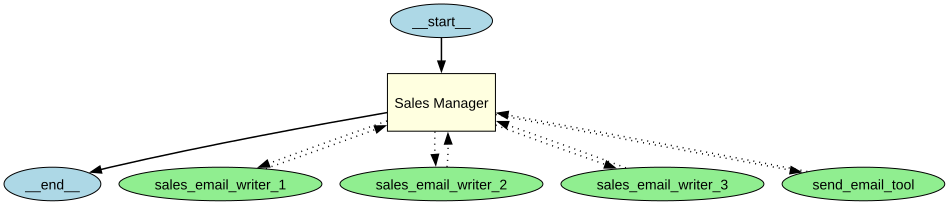

In [40]:
# Visualize the agent graph (manager → tools). Requires graphviz installed.
draw_graph(sales_manager)

In [41]:
# Manager runs the full workflow via tools. Inspect the trace for tool call order.
with trace("Sales Manager"):
    result = await Runner.run(sales_manager, task)

## Part 4: Orchestrating by LLMs via Handoffs

**Tools** = call a specialist and get a result back (manager stays in control).  
**Handoffs** = transfer the conversation to another agent (that agent takes over).

Here: manager drafts with writer tools, then **hands off** to `sales_sender` to pick + send.

### 4.1 via Handoffs

`handoffs=[sales_sender]` exposes a `transfer_to_...` tool. Prefer agent names with letters/digits/underscores only (spaces get rewritten).

In [42]:
# Manager drafts only; sender agent (with send_email_tool) chooses and delivers.
instructions = """
You are a Sales Manager at ComplAI. You get your sales team to
draft emails, then send them all to a sales picker.
"""

task = """
Follow these steps:

1. Generate Drafts: Use each of the three sales_email_writer tools
to generate different email drafts. Just instruct each to write a
sales email; no further details are needed. Do not proceed until
all three drafts are ready, one from each tool.

2. Handoff to the sales_sender to choose and send the best email.
"""

# Writers as tools; send responsibility lives on the handoff target.
tools = [tool1, tool2, tool3]
handoffs = [sales_sender]

sales_manager = Agent(
    name="Sales_Manager",
    instructions=instructions,
    tools=tools,
    handoffs=handoffs,  # transfer control to sales_sender when drafts are ready
    model=MODEL_NAME,
)

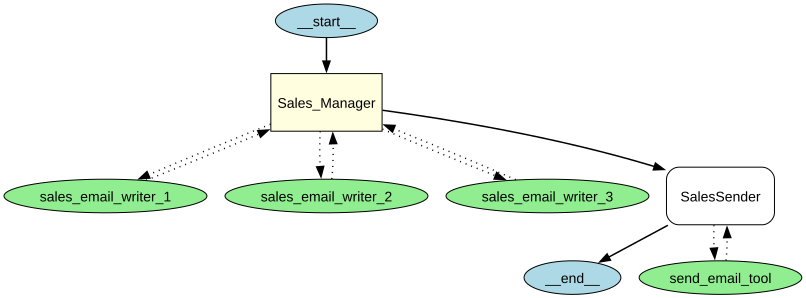

In [43]:
# Graph should show writer tools plus a handoff edge to Sales Sender.
draw_graph(sales_manager)

In [44]:
# Run the handoff workflow. Check the trace: writer tool calls, then transfer_to_sales_sender.
# Warning about spaces in "Sales Sender" is harmless — SDK renames the transfer tool.
with trace("Sales_Manager"):
    result = await Runner.run(sales_manager, task)